# Day 1 - Data foundations practical tasks
***

These tasks cover data preparation, visualization and feature engineering topics.

## Explore the datasets and answer the questions below.
#### Here are some guidlines and advices you should consider:
* you can add as many cells as is comfortable for you for each answer
* some questions require your explanation. Add a cell and choose a markdown option in the menu 
* when you are making plots, please add labels to the axes

For this task you will use red wine dataset

In [2]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
wine_data = pd.read_csv('winequality-red.csv', sep = ';')
wine_data.head()

,fixed acidity,volatile acidity,citric acid,residual sugar,chlorides,free sulfur dioxide,total sulfur dioxide,density,pH,sulphates,alcohol,quality
0,7.4,0.70,0.00,1.9,0.076,11.0,34.0,0.9978,3.51,0.56,9.4,5
1,7.8,0.88,0.00,2.6,0.098,25.0,67.0,0.9968,3.20,0.68,9.8,5
2,7.8,0.76,0.04,2.3,0.092,15.0,54.0,0.9970,3.26,0.65,9.8,5
3,11.2,0.28,0.56,1.9,0.075,17.0,60.0,0.9980,3.16,0.58,9.8,6
4,7.4,0.70,0.00,1.9,0.076,11.0,34.0,0.9978,3.51,0.56,9.4,5


In [14]:
wine_data.info()

<class 'pandas.DataFrame'>
RangeIndex: 1599 entries, 0 to 1598
Data columns (total 12 columns):
 #   Column                Non-Null Count  Dtype  
---  ------                --------------  -----  
 0   fixed acidity         1599 non-null   float64
 1   volatile acidity      1599 non-null   float64
 2   citric acid           1599 non-null   float64
 3   residual sugar        1599 non-null   float64
 4   chlorides             1599 non-null   float64
 5   free sulfur dioxide   1599 non-null   float64
 6   total sulfur dioxide  1599 non-null   float64
 7   density               1599 non-null   float64
 8   pH                    1599 non-null   float64
 9   sulphates             1599 non-null   float64
 10  alcohol               1599 non-null   float64
 11  quality               1599 non-null   int64  
dtypes: float64(11), int64(1)
memory usage: 150.0 KB


In [15]:
wine_data.describe()

,fixed acidity,volatile acidity,citric acid,residual sugar,chlorides,free sulfur dioxide,total sulfur dioxide,density,pH,sulphates,alcohol,quality
count,1599.000000,1599.000000,1599.000000,1599.000000,1599.000000,1599.000000,1599.000000,1599.000000,1599.000000,1599.000000,1599.000000,1599.000000
mean,8.319637,0.527821,0.270976,2.538806,0.087467,15.874922,46.467792,0.996747,3.311113,0.658149,10.422983,5.636023
std,1.741096,0.179060,0.194801,1.409928,0.047065,10.460157,32.895324,0.001887,0.154386,0.169507,1.065668,0.807569
min,4.600000,0.120000,0.000000,0.900000,0.012000,1.000000,6.000000,0.990070,2.740000,0.330000,8.400000,3.000000
25%,7.100000,0.390000,0.090000,1.900000,0.070000,7.000000,22.000000,0.995600,3.210000,0.550000,9.500000,5.000000
50%,7.900000,0.520000,0.260000,2.200000,0.079000,14.000000,38.000000,0.996750,3.310000,0.620000,10.200000,6.000000
75%,9.200000,0.640000,0.420000,2.600000,0.090000,21.000000,62.000000,0.997835,3.400000,0.730000,11.100000,6.000000
max,15.900000,1.580000,1.000000,15.500000,0.611000,72.000000,289.000000,1.003690,4.010000,2.000000,14.900000,8.000000


In [16]:
wine_data.isnull().values.sum()

np.int64(0)

### 1. `quality` attribute in the DataFrame has a score from 0 to 10. How many observations (rows) belong to each score level? 

In [5]:
wine_data.groupby('quality').size().reset_index(name="count")

,quality,count
0,3,10
1,4,53
2,5,681
3,6,638
4,7,199
5,8,18


### 2. Make a bar plot, where we can see distribution of the samples against quality attributes.

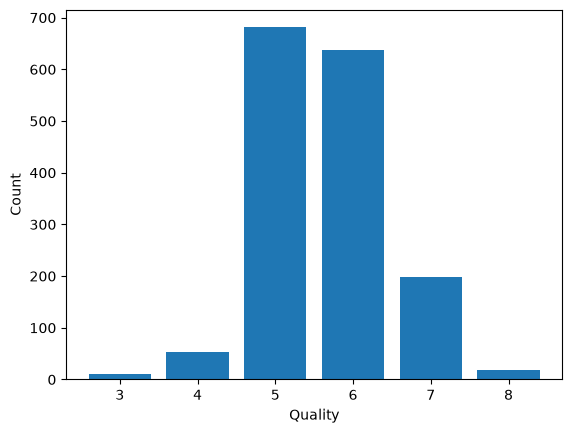

In [14]:
quality_counts = wine_data['quality'].value_counts().sort_index()
plt.bar(quality_counts.index, quality_counts.values)
plt.xlabel("Quality")
plt.ylabel("Count")
# Show graphic
plt.show()

### 3. What is the average value of each feature (column) in each `quality` score level? 

In [7]:
df_mean = wine_data.groupby('quality').mean()
df_mean

,fixed acidity,volatile acidity,citric acid,residual sugar,chlorides,free sulfur dioxide,total sulfur dioxide,density,pH,sulphates,alcohol,Sulfur_dioxide_ratio,Total_acidity
quality,,,,,,,,,,,,,
3,8.360000,0.884500,0.171000,2.635000,0.122500,11.000000,24.900000,0.997464,3.398000,0.570000,9.955000,0.436593,9.415500
4,7.779245,0.693962,0.174151,2.694340,0.090679,12.264151,36.245283,0.996542,3.381509,0.596415,10.265094,0.387507,8.647358
5,8.167254,0.577041,0.243686,2.528855,0.092736,16.983847,56.513950,0.997104,3.304949,0.620969,9.899706,0.339166,8.987981
6,8.347179,0.497484,0.273824,2.477194,0.084956,15.711599,40.869906,0.996615,3.318072,0.675329,10.629519,0.409621,9.118487
7,8.872362,0.403920,0.375176,2.720603,0.076588,14.045226,35.020101,0.996104,3.290754,0.741256,11.465913,0.436107,9.651457
8,8.566667,0.423333,0.391111,2.577778,0.068444,13.277778,33.444444,0.995212,3.267222,0.767778,12.094444,0.406467,9.381111


### 4. What is the median value of each feature (column) in each `quality` score level? 

In [8]:
df_median = wine_data.groupby('quality').median()
df_median

,fixed acidity,volatile acidity,citric acid,residual sugar,chlorides,free sulfur dioxide,total sulfur dioxide,density,pH,sulphates,alcohol,Sulfur_dioxide_ratio,Total_acidity
quality,,,,,,,,,,,,,
3,7.50,0.845,0.035,2.1,0.0905,6.0,15.0,0.997565,3.39,0.545,9.925,0.454082,8.8825
4,7.50,0.670,0.090,2.1,0.0800,11.0,26.0,0.996500,3.37,0.560,10.000,0.391304,8.3000
5,7.80,0.580,0.230,2.2,0.0810,15.0,47.0,0.997000,3.30,0.580,9.700,0.323944,8.6000
6,7.90,0.490,0.260,2.2,0.0780,14.0,35.0,0.996560,3.32,0.640,10.500,0.403620,8.6400
7,8.80,0.370,0.400,2.3,0.0730,11.0,27.0,0.995770,3.28,0.740,11.500,0.450000,9.4700
8,8.25,0.370,0.420,2.1,0.0705,7.5,21.5,0.994940,3.23,0.740,12.150,0.382308,9.0950


### 5. We can notice that for some features raw values differ significantly. Scale the data (except quality column) using Min-Max Scaling manually (create formula yourself). Then use built-in Min-Max Scaling function to validate results (display the resulting data frames separately).
#### Hint: you can use `pd.DataFrame(<your data>)` to display the result of the built-in function in a nicer way.

In [9]:
X = wine_data.drop(columns=["quality"])

data_scaled_manual = (X - X.min()) / (X.max() - X.min())
data_scaled_manual

,fixed acidity,volatile acidity,citric acid,residual sugar,chlorides,free sulfur dioxide,total sulfur dioxide,density,pH,sulphates,alcohol,Sulfur_dioxide_ratio,Total_acidity
0,0.247788,0.397260,0.00,0.068493,0.106845,0.140845,0.098940,0.567548,0.606299,0.137725,0.153846,0.360494,0.240340
1,0.283186,0.520548,0.00,0.116438,0.143573,0.338028,0.215548,0.494126,0.362205,0.209581,0.215385,0.419943,0.289597
2,0.283186,0.438356,0.04,0.095890,0.133556,0.197183,0.169611,0.508811,0.409449,0.191617,0.215385,0.305664,0.282803
3,0.584071,0.109589,0.56,0.068493,0.105175,0.225352,0.190813,0.582232,0.330709,0.149701,0.215385,0.312322,0.574947
4,0.247788,0.397260,0.00,0.068493,0.106845,0.140845,0.098940,0.567548,0.606299,0.137725,0.153846,0.360494,0.240340
...,...,...,...,...,...,...,...,...,...,...,...,...,...
1594,0.141593,0.328767,0.08,0.075342,0.130217,0.436620,0.134276,0.354626,0.559055,0.149701,0.323077,0.844358,0.136730
1595,0.115044,0.294521,0.10,0.089041,0.083472,0.535211,0.159011,0.370778,0.614173,0.257485,0.430769,0.889220,0.108705
1596,0.150442,0.267123,0.13,0.095890,0.106845,0.394366,0.120141,0.416300,0.535433,0.251497,0.400000,0.841634,0.141826
1597,0.115044,0.359589,0.12,0.075342,0.105175,0.436620,0.134276,0.396476,0.653543,0.227545,0.276923,0.844358,0.118471


In [10]:
from sklearn.preprocessing import MinMaxScaler

scaler = MinMaxScaler()
data_scaled_builtin = pd.DataFrame(
    scaler.fit_transform(X),
    columns=X.columns,
    index=X.index
)
data_scaled_builtin

,fixed acidity,volatile acidity,citric acid,residual sugar,chlorides,free sulfur dioxide,total sulfur dioxide,density,pH,sulphates,alcohol,Sulfur_dioxide_ratio,Total_acidity
0,0.247788,0.397260,0.00,0.068493,0.106845,0.140845,0.098940,0.567548,0.606299,0.137725,0.153846,0.360494,0.240340
1,0.283186,0.520548,0.00,0.116438,0.143573,0.338028,0.215548,0.494126,0.362205,0.209581,0.215385,0.419943,0.289597
2,0.283186,0.438356,0.04,0.095890,0.133556,0.197183,0.169611,0.508811,0.409449,0.191617,0.215385,0.305664,0.282803
3,0.584071,0.109589,0.56,0.068493,0.105175,0.225352,0.190813,0.582232,0.330709,0.149701,0.215385,0.312322,0.574947
4,0.247788,0.397260,0.00,0.068493,0.106845,0.140845,0.098940,0.567548,0.606299,0.137725,0.153846,0.360494,0.240340
...,...,...,...,...,...,...,...,...,...,...,...,...,...
1594,0.141593,0.328767,0.08,0.075342,0.130217,0.436620,0.134276,0.354626,0.559055,0.149701,0.323077,0.844358,0.136730
1595,0.115044,0.294521,0.10,0.089041,0.083472,0.535211,0.159011,0.370778,0.614173,0.257485,0.430769,0.889220,0.108705
1596,0.150442,0.267123,0.13,0.095890,0.106845,0.394366,0.120141,0.416300,0.535433,0.251497,0.400000,0.841634,0.141826
1597,0.115044,0.359589,0.12,0.075342,0.105175,0.436620,0.134276,0.396476,0.653543,0.227545,0.276923,0.844358,0.118471


### 6. Create correlation matrix between all variables.

In [11]:
numeric_col = wine_data.select_dtypes(include=[np.number]).columns.tolist()
corr = wine_data[numeric_col].corr()
corr

,fixed acidity,volatile acidity,citric acid,residual sugar,chlorides,free sulfur dioxide,total sulfur dioxide,density,pH,sulphates,alcohol,quality,Sulfur_dioxide_ratio,Total_acidity
fixed acidity,1.000000,-0.256131,0.671703,0.114777,0.093705,-0.153794,-0.113181,0.668047,-0.682978,0.183006,-0.061668,0.124052,-0.130812,0.996384
volatile acidity,-0.256131,1.000000,-0.552496,0.001918,0.061298,-0.010504,0.076470,0.022026,0.234937,-0.260987,-0.202288,-0.390558,-0.072619,-0.204351
citric acid,0.671703,-0.552496,1.000000,0.143577,0.203823,-0.060978,0.035533,0.364947,-0.541904,0.312770,0.109903,0.226373,-0.166939,0.690438
residual sugar,0.114777,0.001918,0.143577,1.000000,0.055610,0.187049,0.203028,0.355283,-0.085652,0.005527,0.042075,0.013732,-0.070626,0.124488
chlorides,0.093705,0.061298,0.203823,0.055610,1.000000,0.005562,0.047400,0.200632,-0.265026,0.371260,-0.221141,-0.128907,-0.105156,0.116675
free sulfur dioxide,-0.153794,-0.010504,-0.060978,0.187049,0.005562,1.000000,0.667666,-0.021946,0.070377,0.051658,-0.069408,-0.050656,0.327241,-0.153614
total sulfur dioxide,-0.113181,0.076470,0.035533,0.203028,0.047400,0.667666,1.000000,0.071269,-0.066495,0.042947,-0.205654,-0.185100,-0.371435,-0.096276
density,0.668047,0.022026,0.364947,0.355283,0.200632,-0.021946,0.071269,1.000000,-0.341699,0.148506,-0.496180,-0.174919,-0.264980,0.675596
pH,-0.682978,0.234937,-0.541904,-0.085652,-0.265026,0.070377,-0.066495,-0.341699,1.000000,-0.196648,0.205633,-0.057731,0.184895,-0.683484
sulphates,0.183006,-0.260987,0.312770,0.005527,0.371260,0.051658,0.042947,0.148506,-0.196648,1.000000,0.093595,0.251397,-0.010459,0.181603


### 7. Plot heatmap to see correlations.

<Axes: >

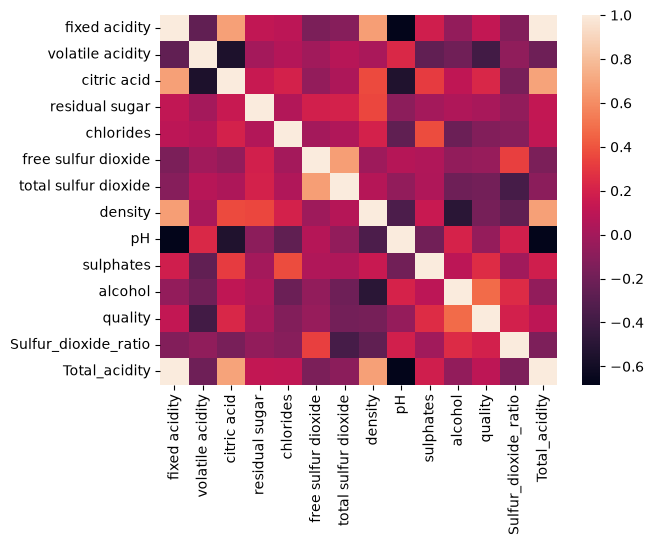

In [12]:
sns.heatmap(corr)

### 8. Identify potential outliers in `alcohol` using the IQR rule. Flag values below `Q1 - 1.5 × IQR` or above `Q3 + 1.5 × IQR`.

In [13]:
q1 = wine_data['alcohol'].quantile(0.25)
q3 = wine_data['alcohol'].quantile(0.75)
iqr = q3 - q1

lower_fence = q1 - 1.5 * iqr
upper_fence = q3 + 1.5 * iqr
potential_outliers = wine_data.loc[
    (wine_data['alcohol'] < lower_fence) | (wine_data['alcohol'] > upper_fence),
    [ 'quality','alcohol']]

print(f"Lower fence: {lower_fence:,.2f}")
print(f"Upper fence: {upper_fence:,.2f}")
potential_outliers

Lower fence: 7.10
Upper fence: 13.50


,quality,alcohol
142,6,14.000000
144,6,14.000000
467,6,14.000000
588,8,14.000000
652,5,14.900000
821,7,14.000000
1114,6,13.600000
1132,7,13.600000
1228,7,13.600000
1269,8,14.000000


### 9. Plot boxplots for all columns (except quality), use figure size 15x6. You can use both original and scaled data for this task. Try to interpret the data for one feature of your choice and write your observations.

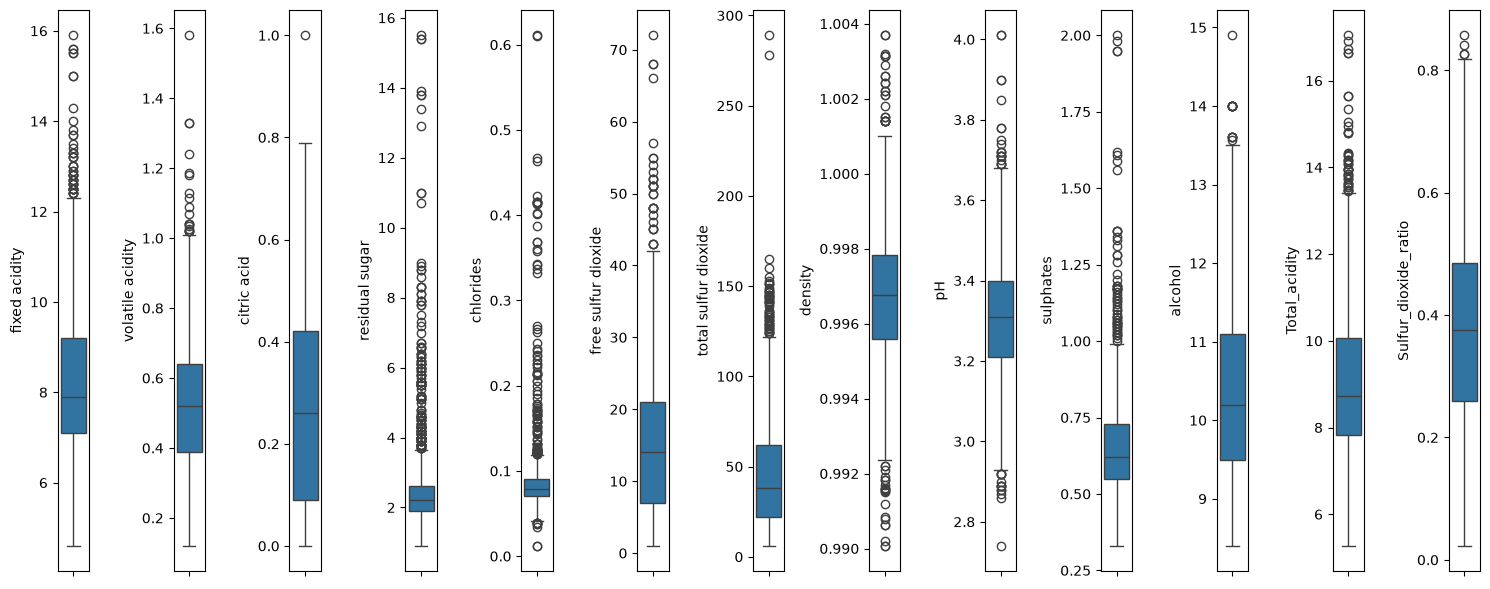

In [37]:
numeric_col = wine_data.select_dtypes(include=[np.number]).columns.drop('quality').tolist()
fig, axes = plt.subplots(nrows=1, ncols=len(numeric_col), figsize=(15, 6))

for idx, feature in enumerate(numeric_col):
    ax = axes[idx]
    sns.boxplot(y=feature, data=wine_data, ax=ax)
    ax.set_xlabel('')
    ax.set_ylabel(feature)

fig.tight_layout()

### 10. Plot boxplot of Ph for each quality type.

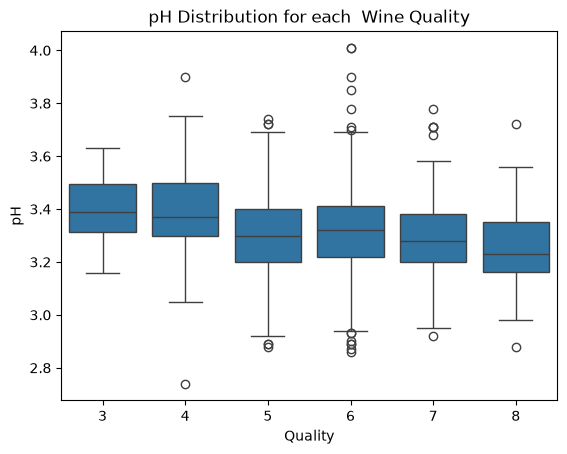

In [15]:

sns.boxplot(x='quality', y='pH', data=wine_data)
plt.xlabel("Quality")
plt.ylabel("pH")
plt.title("pH Distribution for each  Wine Quality")
plt.show()


### 11. Plot a scatter plot of `quality` against the feature with the strongest correlation to it. Does alcohol content appear associated with wine quality?

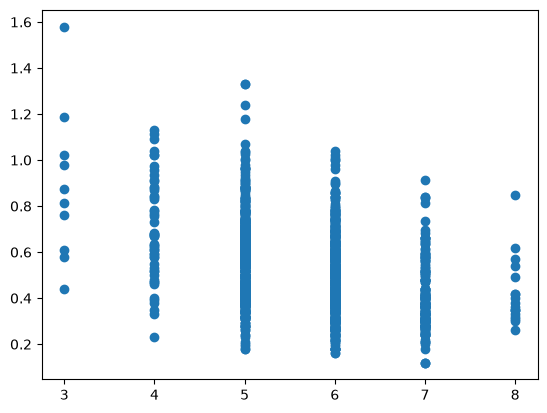

In [13]:
plt.scatter(wine_data['quality'], wine_data['volatile acidity'])

### 12. Plot scatter plot for any two columns and color it by `quality` number. Add color legend and write your observations.

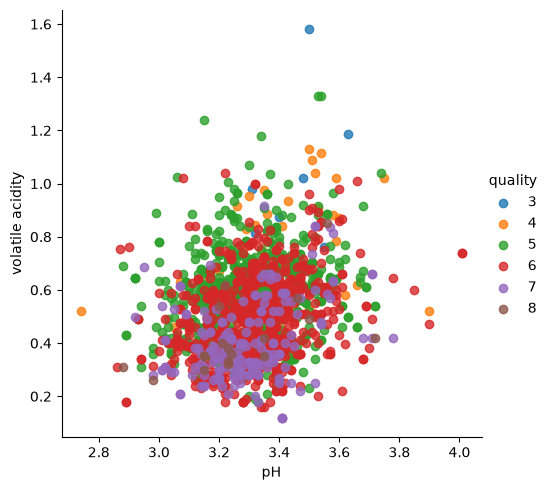

In [18]:

sns.lmplot(x='pH', y='volatile acidity', data=wine_data,hue='quality', fit_reg=False)

### 13. Create X, y for independent variables (all except `quality`) and target variable `quality`, perform k-fold k=3 split on them and calculate and print out the length of training set and testing set for each fold

In [24]:
from sklearn.model_selection import train_test_split
from sklearn.model_selection import KFold
X = wine_data.drop(columns=['quality'])# independent variables except quality
y = wine_data['quality'] # target variable
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)
k = 3 
# Initialize KFold
kf = KFold(n_splits=k, shuffle=True, random_state=42)


In [25]:
fold = 1
for train_index, test_index in kf.split(X):
    # Use .iloc for integer-based indexing
    X_train, X_test = X.iloc[train_index], X.iloc[test_index]
    y_train, y_test = y.iloc[train_index], y.iloc[test_index]

    print(f"Fold {fold}:")
    print(f"X_train:\n{X_train}")
    print(f"y_train:\n{y_train}")
    print(f"X_test:\n{X_test}")
    print(f"y_test:\n{y_test}")
    print()
    fold += 1

Fold 1:
X_train:
      fixed acidity  volatile acidity  citric acid  residual sugar  chlorides  \
0               7.4              0.70         0.00             1.9      0.076   
1               7.8              0.88         0.00             2.6      0.098   
2               7.8              0.76         0.04             2.3      0.092   
3              11.2              0.28         0.56             1.9      0.075   
4               7.4              0.70         0.00             1.9      0.076   
...             ...               ...          ...             ...        ...   
1593            6.8              0.62         0.08             1.9      0.068   
1594            6.2              0.60         0.08             2.0      0.090   
1595            5.9              0.55         0.10             2.2      0.062   
1596            6.3              0.51         0.13             2.3      0.076   
1598            6.0              0.31         0.47             3.6      0.067   

      free

### 14. Create two new features:
- Sulfur dioxide ratio (`free sulfur dioxide` / `total sulfur dioxide`)
- Total acidity (`fixed acidity` + `volatile acidity` + `citric acid`)

In [3]:
wine_data["Sulfur_dioxide_ratio"] = wine_data["free sulfur dioxide"] / wine_data["total sulfur dioxide"] 
wine_data["Total_acidity"] = wine_data["fixed acidity"] + wine_data["volatile acidity"] + wine_data["citric acid"]
wine_data


,fixed acidity,volatile acidity,citric acid,residual sugar,chlorides,free sulfur dioxide,total sulfur dioxide,density,pH,sulphates,alcohol,quality,Sulfur_dioxide_ratio,Total_acidity
0,7.4,0.700,0.00,1.9,0.076,11.0,34.0,0.99780,3.51,0.56,9.4,5,0.323529,8.100
1,7.8,0.880,0.00,2.6,0.098,25.0,67.0,0.99680,3.20,0.68,9.8,5,0.373134,8.680
2,7.8,0.760,0.04,2.3,0.092,15.0,54.0,0.99700,3.26,0.65,9.8,5,0.277778,8.600
3,11.2,0.280,0.56,1.9,0.075,17.0,60.0,0.99800,3.16,0.58,9.8,6,0.283333,12.040
4,7.4,0.700,0.00,1.9,0.076,11.0,34.0,0.99780,3.51,0.56,9.4,5,0.323529,8.100
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
1594,6.2,0.600,0.08,2.0,0.090,32.0,44.0,0.99490,3.45,0.58,10.5,5,0.727273,6.880
1595,5.9,0.550,0.10,2.2,0.062,39.0,51.0,0.99512,3.52,0.76,11.2,6,0.764706,6.550
1596,6.3,0.510,0.13,2.3,0.076,29.0,40.0,0.99574,3.42,0.75,11.0,6,0.725000,6.940
1597,5.9,0.645,0.12,2.0,0.075,32.0,44.0,0.99547,3.57,0.71,10.2,5,0.727273,6.665


### 15. Create a sample dataset with dates for a whole week. Extract day of the week with `dayofweek` function (0=Monday, 6=Sunday). Additionally flag weekends by creating another new `is_weekend` feature.

In [4]:
# Sample dataset with a date column
date_data = {'date': [
    '2026-11-01', '2026-11-02', '2026-11-03',
    '2026-11-04', '2026-11-05', '2026-11-06', '2026-11-07'
]}
df = pd.DataFrame(date_data)

# Convert the 'date' column to a datetime object
df['date'] = pd.to_datetime(df['date'])

# Extract features from the date
df['year'] = df['date'].dt.year          # Extract year
df['month'] = df['date'].dt.month        # Extract month
df['day'] = df['date'].dt.day            # Extract day
df['day_of_week'] = df['date'].dt.dayofweek  # Extract day of the week (0=Monday, 6=Sunday)
df['is_weekend'] = df['day_of_week'].apply(lambda x: 1 if x >= 5 else 0)  # Weekend flag
df['quarter'] = df['date'].dt.quarter    # Extract quarter
df['day_of_year'] = df['date'].dt.dayofyear  # Extract day of the year

# Display the resulting DataFrame
df

C:\Users\anugraheetha.bin.saj\AppData\Local\Temp\ipykernel_22876\564646858.py:15: Pandas4Warning: Series.dt.dayofweek is deprecated and will be removed in a future version. Use Series.dt.day_of_week instead.
  df['day_of_week'] = df['date'].dt.dayofweek  # Extract day of the week (0=Monday, 6=Sunday)
C:\Users\anugraheetha.bin.saj\AppData\Local\Temp\ipykernel_22876\564646858.py:18: Pandas4Warning: Series.dt.dayofyear is deprecated and will be removed in a future version. Use Series.dt.day_of_year instead.
  df['day_of_year'] = df['date'].dt.dayofyear  # Extract day of the year


,date,year,month,day,day_of_week,is_weekend,quarter,day_of_year
0,2026-11-01,2026,11,1,6,1,4,305
1,2026-11-02,2026,11,2,0,0,4,306
2,2026-11-03,2026,11,3,1,0,4,307
3,2026-11-04,2026,11,4,2,0,4,308
4,2026-11-05,2026,11,5,3,0,4,309
5,2026-11-06,2026,11,6,4,0,4,310
6,2026-11-07,2026,11,7,5,1,4,311
